# Panel 7 of tbfit: exact diagonalisation, spectra and maps

This notebook explains **exactly** what panel 7 ("7. ED: spectra and maps") computes. Every equation is followed by the code that implements it. Where possible the code is the same function the GUI calls (`tbmany`, `tbcore`). Each important result is then checked against an independent calculation: brute-force matrices in the full Fock space, analytic results for the Hubbard dimer, sum rules and the $U = 0$ limit.

**What panel 7 does, in one line.** It takes the reduced model of tab 2 (site energies $\varepsilon_i$, hoppings $t_{ij}$), adds an on-site Hubbard $U_i$ on every reduced site and solves the many-body problem exactly on a finite piece of chain. From the eigenstates it computes what an STM tip would measure: inelastic spin-flip steps (IETS) and elastic charge peaks (addition and removal of one electron), with their spatial maps.

| step | what | where in the GUI | section |
|---|---|---|---|
| 1 | atomistic TB and the fitted reduced model $\varepsilon_i, t_{ij}$ | tabs 1 and 2 | 1 |
| 2 | Wannier-like orbitals $w_i(\mathbf{x})$ of the reduced sites | used for $U_i$ and all maps | 2 |
| 3 | on-site interaction $U_i$ (fitted in tab 6, projected, or manual) | box 1 | 3 |
| 4 | cluster Hamiltonian on `cells` copies (open chain or ring, partial last cell) | box 2 | 4 |
| 5 | exact diagonalisation in the sector of lowest $\lvert S_z\rvert$ | box 2, "Run ED" | 5 |
| 6 | total spin, levels, ground-state charges, moments, correlations | text output, map (default view) | 6, 7 |
| 7 | spin-flip transitions: weights, selection rules, classification | spectrum panel (orange dots), table | 8, 9 |
| 8 | spin-flip maps and the inelastic tip spectrum (IETS) | click a level; lower-right panel | 10, 11 |
| 9 | charge excitations $N\pm1$, tip spectrum $A_v(E)$, Dyson maps | box 3, lower-left panel, click a peak | 12, 13, 14 |

The running example is the **olympicene radical chain** (`examples/olympicene_chain.hex` with `olympicene_chain_hex.eff`): two sites per cell (A, B = the two olympicenyl units of the dimer cell), one electron per site. We use an even chain of 4 units (2 cells, singlet ground state) and an odd chain of 5 units (3 cells, the last one keeping only A, doublet ground state). Section 15 adds the goblet chain, where some reduced sites carry a local moment and others do not. Section 16 maps every GUI element to its formula and lists the approximations.

**Requirements.** The tbfit version that has odd chains (`tbmany.cluster_keep`). Put this notebook in the `tbfit` folder, in `tbfit/notebooks`, or next to the `tbfit` folder, or set the environment variable `TBFIT_DIR`. Running all the cells takes less than a minute.

In [1]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from math import comb
import scipy.sparse as sp
from scipy.spatial import cKDTree

# find the tbfit folder (the one with tbcore.py and tbmany.py)
cands = [os.environ.get("TBFIT_DIR", ""), ".", "..", "./tbfit", "../tbfit", os.path.expanduser("~/tbfit")]
found = [os.path.abspath(p) for p in cands if p and os.path.exists(os.path.join(p, "tbmany.py"))]
if not found:
    raise FileNotFoundError("tbfit not found: set TBFIT_DIR to the folder that contains tbmany.py")
TBFIT = found[0]
sys.path.insert(0, TBFIT)
import tbcore as tb, tbmany as tm
assert hasattr(tm, "cluster_keep"), "this notebook needs the tbfit version with odd chains (tbmany.cluster_keep)"
EX = os.path.join(TBFIT, "examples")
print("tbfit from", TBFIT)

np.set_printoptions(precision=4, suppress=True, linewidth=120)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 9})

tbfit from /home/claude/tbfit


## 1. The starting point: atomistic TB and the reduced model of tab 2

**Atomistic tight binding (tab 1).** One $p_z$ orbital per carbon $x$, hoppings to the first three neighbour shells ($t_1=-2.7$, $t_2=-0.20$, $t_3=-0.18$ eV by default):

$$H_\mathrm{TB}=\sum_{xy,\sigma} h_{xy}\,c^\dagger_{x\sigma}c_{y\sigma},\qquad H_\mathrm{TB}(k)=\sum_R h(R)\,e^{ikR}.$$

The Fermi level $E_F$ is placed at mid-gap for the neutral chain (one $\pi$ electron per carbon).

**Reduced model (tab 2).** A few sites $i$ per cell (here A and B) with the Bloch Hamiltonian

$$H_\mathrm{eff}(k)_{ij}=\sum_R h^\mathrm{eff}_{ij}(R)\,e^{ikR},\qquad h^\mathrm{eff}_{ii}(0)=\varepsilon_i,\quad h^\mathrm{eff}_{ij}(R)=t_{ij}(R).$$

Its parameters are fitted by least squares to the TB bands of the chosen window, $\min\sum_{k,n}[\epsilon^\mathrm{eff}_n(k)-\epsilon^\mathrm{TB}_n(k)]^2$. **Panel 7 uses these fitted numbers** (`r["params"]`) for all one-body terms, and it uses $E_F$ of the TB as the energy zero.

The model file says: sites A and B, two bands around $E_F$ (`bands 0 1`), one on-site energy `e`, nearest-neighbour hopping `t` (A-B in the cell and B-A' to the next cell, equivalent by the glide) and a second-neighbour hopping `t2` (A-A', B-B').

bands 0 1
site A atom 20
site B atom 17
onsite A e
onsite B e
hop A B 0 t
hop B A 1 t
hop A A 1 t2
hop B B 1 t2

38 carbons per cell, period |T| = 17.217 A, E_F = 0.4187 eV
fitted parameters (eV): {'e': 0.41882, 't': 0.05, 't2': 5e-05}    band rms 0.053 meV
eps - E_F = +0.00010 eV (the ED measures energies from E_F)


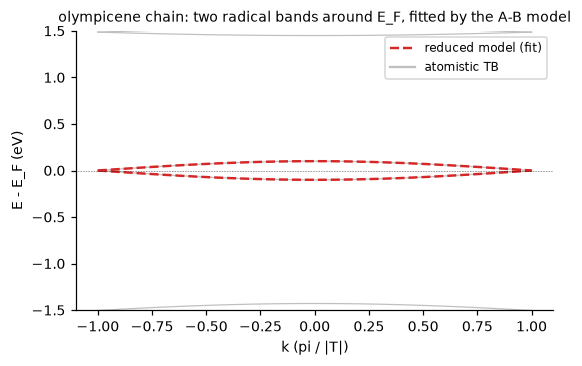

In [2]:
st = tb.load_structure(os.path.join(EX, "olympicene_chain.hex"))
model_text = open(os.path.join(EX, "olympicene_chain_hex.eff")).read()
m = tb.parse_eff(model_text, st)
H = tb.hoppings(st)                  # atomistic TB (tab 1)
r = tb.fit(H, st, m)                 # tab 2 fit
pv, EF = r["params"], r["EF"]
print("\n".join(l for l in model_text.splitlines() if l and not l.startswith("#")))
print(f"\n{st.N} carbons per cell, period |T| = {np.linalg.norm(st.T):.3f} A, E_F = {EF:.4f} eV")
print("fitted parameters (eV):", {k: round(float(v), 5) for k, v in pv.items()},
      f"   band rms {1e3 * r['rms']:.3f} meV")
print(f"eps - E_F = {pv['e'] - EF:+.5f} eV (the ED measures energies from E_F)")

fig, ax = plt.subplots(figsize=(5.2, 3.4))
ks = r["ks"] / np.pi
ax.plot(ks, r["E_tb"] - EF, color="0.75", lw=0.8)
for n in range(r["E_eff"].shape[1]):
    ax.plot(ks, r["E_eff"][:, n] - EF, color="tab:red", lw=1.6, ls="--", label="reduced model (fit)" if n == 0 else None)
ax.plot([], [], color="0.75", label="atomistic TB")
ax.set_ylim(-1.5, 1.5); ax.set_xlabel("k (pi / |T|)"); ax.set_ylabel("E - E_F (eV)")
ax.axhline(0, color="k", lw=0.4, ls=":"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("olympicene chain: two radical bands around E_F, fitted by the A-B model")
plt.tight_layout(); plt.show()

The two radical bands have a width of about $4t = 0.2$ eV and are isolated from the other $\pi$ bands by more than 1 eV, so a two-site model per cell describes them almost exactly (rms below 0.1 meV). With $t = 0.05$ eV and $U_i$ of about 0.5 eV (section 3) the chain is in the regime $U \gg t$: one electron per unit and antiferromagnetic superexchange $J \approx 4t^2/U$ of about 20 meV.

## 2. Wannier-like orbitals of the reduced sites

The reduced model has no atoms, but the tip sees atoms. `tbmany.wannier_orbitals` builds, for every reduced site, an orthonormal orbital on the carbons that spans exactly the fitted bands (Löwdin-orthogonalised projection):

1. at every $k$ (64 points): TB eigenvectors $\lvert\psi_{mk}\rangle$ of the bands in the window, and the trial orbital $\lvert g_i\rangle$ of site $i$ (normalised on the atoms named in `site ... atom ...`);
2. overlap $A_{mi}(k)=\langle\psi_{mk}\vert g_i\rangle$ and $S(k)=A^\dagger A$;
3. $\lvert w_{ik}\rangle=\sum_m \lvert\psi_{mk}\rangle\,[A\,S^{-1/2}]_{mi}$, orthonormal at every $k$;
4. back to real space: $w_i(\mathbf{x}+R\,\mathbf{T})=\frac{1}{N_k}\sum_k e^{ikR}\,w_{ik}(\mathbf{x})$, kept for $\lvert R\rvert\le 4$ cells.

Properties used below:

* $\langle w_{i,0}\vert w_{j,R}\rangle=\delta_{ij}\delta_{R0}$ (orthonormal), and $\sum_i\lvert w_i\rangle\langle w_i\rvert$ is the projector on the model bands;
* $\langle w_{i,0}\vert H_\mathrm{TB}\vert w_{j,R}\rangle$ are the *projected* hoppings. They reproduce the bands exactly, and they are the starting point of the fit of tab 2;
* the smallest eigenvalue of $S(k)$ over $k$ ("projection overlap") measures how well the trial orbitals represent the bands. It is 0.22 here because each trial orbital is a single atom, while the radical orbital is spread over the unit. The Löwdin step still gives the correct orbitals.

Spread of an orbital: the inverse participation ratio $\mathrm{IPR}_i=\sum_\mathbf{x}\lvert w_i(\mathbf{x})\rvert^4$ (1 for one atom, $1/n$ for $n$ equal atoms) and the number of atoms that hold 90% of $\lvert w_i\rvert^2$ (the column "atoms 90%" in box 1).

In [3]:
w, hR, smin = tm.wannier_orbitals(H, st, m)
ipr, n90 = tm.orbital_spread(w)
for i, name in enumerate(m.sites):
    print(f"site {name}: IPR = {ipr[i]:.4f}  (1/IPR = {1 / ipr[i]:.1f} atoms),  atoms holding 90%: {n90[i]}")
print(f"projection overlap (min eigenvalue of S(k)): {smin:.3f}")

# checks: orthonormality and projected hoppings
Rs = sorted(w)
ovl = lambda R: sum(w[Rp].T @ w[Rp - R] for Rp in Rs if Rp - R in w)
print("<w_i,0|w_j,0> =\n", ovl(0), "\n<w_i,0|w_j,1> =\n", ovl(-1))
print("projected hoppings h(R=0) - E_F on the diagonal:\n", hR[0] - EF * np.eye(2), "\nh(R=1):\n", hR[1])

site A: IPR = 0.1404  (1/IPR = 7.1 atoms),  atoms holding 90%: 7
site B: IPR = 0.1404  (1/IPR = 7.1 atoms),  atoms holding 90%: 7
projection overlap (min eigenvalue of S(k)): 0.223
<w_i,0|w_j,0> =
 [[ 1. -0.]
 [-0.  1.]] 
<w_i,0|w_j,1> =
 [[ 0.  0.]
 [-0.  0.]]
projected hoppings h(R=0) - E_F on the diagonal:
 [[0.0001 0.05  ]
 [0.05   0.0001]] 
h(R=1):
 [[0.   0.  ]
 [0.05 0.  ]]


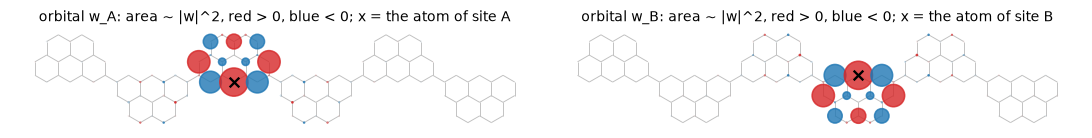

In [4]:
def bonds_of(P, cut=1.6):
    return cKDTree(P).query_pairs(cut, output_type="ndarray")

fig, axs = plt.subplots(1, 2, figsize=(10, 2.6))
P = np.concatenate([st.xy + R * st.T for R in (-1, 0, 1)])
for i, ax in enumerate(axs):
    amp = np.concatenate([w[R][:, i] for R in (-1, 0, 1)])
    ax.add_collection(LineCollection(P[bonds_of(P)], colors="0.75", linewidths=0.6))
    ax.scatter(*P.T, s=1500 * amp ** 2, c=np.where(amp > 0, "tab:red", "tab:blue"), alpha=0.8, zorder=3)
    ax.scatter(*st.xy[m.site_atom[i]].T, marker="x", color="k", s=40, zorder=4)
    ax.set_aspect("equal"); ax.set_axis_off()
    ax.set_title(f"orbital w_{m.sites[i]}: area ~ |w|^2, red > 0, blue < 0; x = the atom of site {m.sites[i]}")
plt.tight_layout(); plt.show()

Each orbital is the singly occupied molecular orbital (SOMO) of one olympicenyl unit. It is not a single atom: a "site" of the reduced model is a whole unit. This is why every map below is drawn on the atoms through $w_i(\mathbf{x})$, and why a spin-flip or charge map of a single site already looks like a molecular orbital. The Löwdin orthogonalisation adds small tails on the neighbouring units.

## 3. The on-site interaction $U_i$: the three choices of box 1

**Projected ("U_atom sum|w|^4").** Start from the atomic Hubbard interaction $U\sum_\mathbf{x} n_{\mathbf{x}\uparrow}n_{\mathbf{x}\downarrow}$ ($U \approx 3$ eV for graphene $\pi$ electrons). Keep only the part of $c_{\mathbf{x}\sigma}$ inside the model bands, $c_{\mathbf{x}\sigma}\to\sum_a w_a(\mathbf{x})\,c_{a\sigma}$. Then

$$U\sum_\mathbf{x} n_{\mathbf{x}\uparrow}n_{\mathbf{x}\downarrow}\;\to\;\sum_{abcd}U\,O_{abcd}\;c^\dagger_{a\uparrow}c_{b\uparrow}c^\dagger_{c\downarrow}c_{d\downarrow},\qquad O_{abcd}=\sum_\mathbf{x} w_a(\mathbf{x})w_b(\mathbf{x})w_c(\mathbf{x})w_d(\mathbf{x}).$$

The on-site term is $U_a = U\,O_{aaaa} = U\,\mathrm{IPR}_a$: a more spread orbital feels a smaller $U$. **Panel 7 keeps only these on-site terms.** Tab 4 can also keep the inter-site terms (option "full projected interaction").

**Fitted ("U fitted in tab 6", the default).** Tab 5 solves the atomistic mean-field Hubbard model; tab 6 fits the $U_i$ of the reduced model, with $\varepsilon_i$ and $t_{ij}$ fixed, so that the reduced mean field

$$H_\sigma = H_t+\sum_i U_i\left(\langle n_{i,-\sigma}\rangle-\tfrac12\right)n_{i\sigma}$$

reproduces the spin-resolved atomistic mean-field bands of the selected magnetic states (and, if ticked, their moments). One free rigid offset per state absorbs the overall Hartree shift. The fitted $U_i$ contain the mean-field response of the other $\pi$ bands, which the projection ignores. Neither value is "the" exact $U$: the projection neglects the other bands, and the fit imports their *mean-field* response, which is not the same as many-body screening.

**Manual.** Any numbers typed in the $U_i$ column.

Below we reproduce tabs 5 and 6 for the olympicene chain in a few lines, with the same calls as the GUI.

In [5]:
U_atom = 3.0
U_proj = U_atom * ipr
print("projected U_i = U_atom * IPR_i:", dict(zip(m.sites, np.round(U_proj, 4))))

# tab 5: atomistic mean field, no sites to choose
mf = tm.mfh_scan(H, st, U=U_atom, nk=24, kT=0.005)
for o in mf:
    print(f"  tab 5 state: {o['label']:28s} E - E_min = {1e3 * (o['sol']['E'] - mf[0]['sol']['E']):8.2f} meV/cell, max |m| = {o['mmax']:.3f}")

# tab 6: the two magnetic states as references, one U for A and B (they are equivalent)
chosen = [o for o in mf if o["mmax"] > 0.05]
Nmod, _ = tm.neutral_filling(m, r)
refs = []
for o in chosen:
    ref = tm.mfh_reference(H, st, m, o["sol"], U_atom, 0.005)
    two_sz = o["sol"]["n_up"] - o["sol"]["n_dn"]
    ref["n_up_mod"], ref["n_dn_mod"] = (Nmod + two_sz) / 2, (Nmod - two_sz) / 2
    refs.append(ref)
fitU = tm.fit_U_to_mfh(m, pv, refs, [0, 0], [U_proj[0]], 0.005, moment_weight=0.1)
U_fit = np.array([fitU["U_group"][0]] * 2)
print(f"tab 6 fit: U = {U_fit[0]:.4f} eV (projected {U_proj[0]:.4f}); band rms per state (meV):",
      np.round(1e3 * np.array(fitU["rms"]), 2))

projected U_i = U_atom * IPR_i: {'A': np.float64(0.4212), 'B': np.float64(0.4212)}


  tab 5 state: S_z = 0 (sublattice start)   E - E_min =     0.00 meV/cell, max |m| = 0.296
  tab 5 state: S_z = 1 (all up start)       E - E_min =    35.84 meV/cell, max |m| = 0.301
  tab 5 state: non-magnetic (S_z = 0)       E - E_min =   184.22 meV/cell, max |m| = 0.000


tab 6 fit: U = 0.5661 eV (projected 0.4212); band rms per state (meV): [9.19 9.29]


The fitted value is about 35% larger than the projected one. In the rest of the notebook we use the **fitted** $U$ (the panel 7 default). Section 11 shows how the spin excitation energies scale with $U$.

## 4. The cluster Hamiltonian (box 2)

With `cells` $=N_c$ copies of the unit cell, the cluster sites are $a=(c,i)$ with index $a=c\,n_s+i$ (labels `A0 B0 A1 ...`, where the digit is the cell). Panel 7 solves

$$\boxed{H=\sum_{ab,\sigma}T_{ab}\,c^\dagger_{a\sigma}c_{b\sigma}+\sum_a U_a\left(n_{a\uparrow}-\tfrac12\right)\left(n_{a\downarrow}-\tfrac12\right)}$$

with

* $T_{aa}=\varepsilon_i-E_F$, and $T_{ab}=t_{ij}(R)$ for every term of the model between cell $c$ and cell $c+R$. For an **open chain** the terms that leave the cluster are dropped; for a **ring** $c+R$ is taken modulo $N_c$;
* **partial last cell** ("last cell keeps sites", e.g. `A`): the rows and columns of the other sites of the last cell are removed. Everything else (hoppings, $U_a$, orbitals) is the same as in the full cluster. Open chains only;
* $U_a=U_i$ from box 1 (only on-site terms in panel 7).

**Why the particle-hole form $U(n_\uparrow-\frac12)(n_\downarrow-\frac12)$.** Expanding it,

$$U\left(n_\uparrow-\tfrac12\right)\left(n_\downarrow-\tfrac12\right)=U\,n_\uparrow n_\downarrow-\tfrac U2\,(n_\uparrow+n_\downarrow)+\tfrac U4 .$$

The fitted $\varepsilon_i$ already contain the average repulsion of the neutral, half-filled system (they come from a TB fitted to the real bands). For an uncorrelated half-filled site ($\langle n_\sigma\rangle=\frac12$) the particle-hole term vanishes on average, so the Hartree energy is not counted twice. It also makes the model particle-hole symmetric when $\varepsilon_i=E_F$ on a bipartite lattice: addition and removal energies are then symmetric around $E_F=0$.

**In the code** (`build_cluster` with `ph=True`): the one-body matrix becomes `Tup = Tdn = T - diag(U/2)`, the interaction is the list of terms `(a, a, a, a, U_a)` meaning $U_a\,n_{a\uparrow}n_{a\downarrow}$, and the constant $\sum_a U_a/4$ is dropped. That constant is the same for every state and every electron number, so it cancels in every excitation energy, including $E(N\pm1)-E(N)$.

**Electron number (blank = neutral).** $N_e = n_\mathrm{cell}\times N_s/n_s$ rounded, where $n_\mathrm{cell}=2\times$(number of fitted bands below $E_F$, averaged over $k$) is the number of electrons per cell in the model bands. This is one per site only when half of the model bands are occupied. For the olympicene chain $n_\mathrm{cell}=2$, so 4 electrons on 4 sites and 5 on 5.

In [6]:
def panel7_cluster(ncells, U_site, keep_last=None, periodic=False):
    # exactly the call of the GUI (tbgui.e6_run_ed): on-site U_i given per site name, ph form
    Uov = {name: float(U_site[k]) for k, name in enumerate(m.sites)}
    return tm.build_cluster(H, st, m, pv, ncells=ncells, periodic=periodic, U=U_atom, mode="onsite",
                            EF=EF, U_override=Uov, ph=True, keep_last=keep_last)

def neutral(cl, ncells):
    return tm.neutral_filling(m, r, ncells, len(cl["kept"]))[0]

cl4 = panel7_cluster(2, U_fit)                     # 4 units: A0 B0 A1 B1
cl5 = panel7_cluster(3, U_fit, keep_last=["A"])    # 5 units: A0 B0 A1 B1 A2
for name, cl, nc in (("even chain", cl4, 2), ("odd chain", cl5, 3)):
    Ns, ne = len(cl["T"]), neutral(cl, nc)
    nu = (ne + ne % 2) // 2
    print(f"{name}: sites {cl['labels']}, {ne} electrons, sector N_up = {nu}, N_dn = {ne - nu}, "
          f"dimension C({Ns},{nu}) C({Ns},{ne - nu}) = {comb(Ns, nu) * comb(Ns, ne - nu)}")
print("\nT (eV) of the odd chain (diagonal = eps - E_F):\n", cl5["T"])
print("U_a (eV):", cl5["U_site"])
print("diagonal of Tup = T - U/2:", np.diag(cl5["Tup"]))

even chain: sites ['A0', 'B0', 'A1', 'B1'], 4 electrons, sector N_up = 2, N_dn = 2, dimension C(4,2) C(4,2) = 36
odd chain: sites ['A0', 'B0', 'A1', 'B1', 'A2'], 5 electrons, sector N_up = 3, N_dn = 2, dimension C(5,3) C(5,2) = 100

T (eV) of the odd chain (diagonal = eps - E_F):
 [[0.0001 0.05   0.     0.     0.    ]
 [0.05   0.0001 0.05   0.     0.    ]
 [0.     0.05   0.0001 0.05   0.    ]
 [0.     0.     0.05   0.0001 0.05  ]
 [0.     0.     0.     0.05   0.0001]]
U_a (eV): [0.5661 0.5661 0.5661 0.5661 0.5661]
diagonal of Tup = T - U/2: [-0.283 -0.283 -0.283 -0.283 -0.283]


## 5. Exact diagonalisation

**Fock space and sector.** For one spin species a configuration is a bit string $\alpha$ of $N_s$ bits with $N_\sigma$ ones. $H$ conserves $N_\uparrow$ and $N_\downarrow$, so it is diagonalised in one sector $(N_\uparrow,N_\downarrow)$ of dimension

$$D=\binom{N_s}{N_\uparrow}\binom{N_s}{N_\downarrow}.$$

Panel 7 uses the sector of **lowest** $\lvert S_z\rvert$: $2S_z=N_e \bmod 2$, i.e. $N_\uparrow=N_\downarrow$ for even $N_e$ and $N_\uparrow=N_\downarrow+1$ for odd $N_e$. Every spin multiplet $S$ has members $M=-S,\dots,S$ and $S\ge\lvert M_\mathrm{min}\rvert$, so **each multiplet appears exactly once** in this sector. Counting states in the list therefore counts multiplets. For example, 4 spins-1/2 give $\binom42=6$ states: 2 singlets, 3 triplets, 1 quintet.

**Signs.** Modes are ordered $1\!\uparrow,\dots,N_s\!\uparrow,1\!\downarrow,\dots,N_s\!\downarrow$ (Jordan-Wigner). $c^\dagger_{i\sigma}$ acting on a bit string gives $(-1)^{(\text{occupied modes of species }\sigma\text{ below }i)}$, and a down operator also picks up $(-1)^{N_\uparrow}$ from passing all up modes. That factor is constant in a sector and cancels in $c^\dagger_{a\downarrow}c_{b\downarrow}$, but it matters for $S^\pm$ and for adding or removing a down electron (section 12).

**Matrix trick.** A state is stored as a matrix $\Psi[\alpha,\beta]$ (up configuration, down configuration), and

$$H\Psi=\hat T_\uparrow\Psi+\Psi\,\hat T_\downarrow^{\,T}+D\circ\Psi,\qquad (\hat T_\sigma)_{\alpha\alpha'}=\langle\alpha\vert\textstyle\sum_{ab}T^\sigma_{ab}c^\dagger_a c_b\vert\alpha'\rangle,\quad D_{\alpha\beta}=\sum_a U_a\,n_a(\alpha)\,n_a(\beta).$$

The full $D\times D$ matrix is never built. $\hat T_\sigma$ is sparse, of size $\binom{N_s}{N_\sigma}^2$. If $D\le2500$ the code builds $H$ column by column and uses dense `eigh` (all eigenvalues exact); otherwise it uses Lanczos (ARPACK `eigsh`, `which="SA"`, `tol=1e-10`) for the lowest `states` eigenpairs. Box 2 refuses $D>3\times10^6$.

### 5.1 Check: the Hubbard dimer, analytically and by brute force

Two sites, $T=\begin{pmatrix}0&-t\\-t&0\end{pmatrix}$, $U$ on both, two electrons. In the $S_z=0$ sector (basis $\lvert\uparrow,\downarrow\rangle,\lvert\downarrow,\uparrow\rangle,\lvert\uparrow\downarrow,0\rangle,\lvert0,\uparrow\downarrow\rangle$) with the particle-hole form (constant $U/2$ included):

$$E_{S=0}^{\pm}=\pm\tfrac12\sqrt{U^2+16t^2},\qquad E_{T}=-\tfrac U2,\qquad E_\mathrm{ionic}=+\tfrac U2 .$$

The singlet-triplet gap is $J=E_T-E_{S}^-=\tfrac12\left(\sqrt{U^2+16t^2}-U\right)\to 4t^2/U$ for $U\gg t$. `tbmany` drops the constant $\sum_a U_a/4=U/2$, so its energies are lower by $U/2$.

The brute-force code below builds all operators $c_m$ as $2^{2N_s}\times2^{2N_s}$ sparse matrices (Jordan-Wigner strings), $H$ as written above, and diagonalises it at fixed $N$ (all $S_z$ together). It shares no code with `tbmany` and is used for all the checks in this notebook.

In [7]:
def fock_ops(Ns):
    # annihilators c_m, m = s * Ns + i (all up modes first), as sparse 4^Ns x 4^Ns matrices
    M = 2 * Ns
    a = sp.csr_matrix(np.array([[0.0, 1.0], [0.0, 0.0]]))   # c on one mode, basis (|0>, |1>)
    Z, I = sp.diags([1.0, -1.0]), sp.identity(2)
    ops = []
    for mo in range(M):
        out = None
        for k, o in enumerate([Z] * mo + [a] + [I] * (M - mo - 1)):
            out = o if out is None else sp.kron(out, o, format="csr")
        ops.append(out.tocsr())
    return ops

def brute_force(T, U, n_el):
    # H = sum T_ab c+_as c_bs + sum U_a (n_a,up - 1/2)(n_a,dn - 1/2) at fixed N (all S_z)
    Ns = len(T)
    c = fock_ops(Ns)
    cu, cd = c[:Ns], c[Ns:]
    num = lambda o: (o.T @ o).tocsr()
    one = sp.identity(4 ** Ns, format="csr")
    Hf = sum(T[i, j] * (cu[i].T @ cu[j] + cd[i].T @ cd[j]) for i in range(Ns) for j in range(Ns) if T[i, j] != 0)
    Hf = Hf + sum(U[i] * (num(cu[i]) - 0.5 * one) @ (num(cd[i]) - 0.5 * one) for i in range(Ns))
    Ntot = sum(num(o) for o in c).diagonal()
    idx = np.where(np.abs(Ntot - n_el) < 1e-9)[0]
    E, V = np.linalg.eigh(Hf.toarray()[np.ix_(idx, idx)])
    sub = lambda o: o.toarray()[np.ix_(idx, idx)]
    Sx = [sub(0.5 * (cu[i].T @ cd[i] + cd[i].T @ cu[i])) for i in range(Ns)]
    Sy = [sub(-0.5j * (cu[i].T @ cd[i] - cd[i].T @ cu[i])) for i in range(Ns)]
    Sz = [sub(0.5 * (num(cu[i]) - num(cd[i]))) for i in range(Ns)]
    S2 = sum(Sx) @ sum(Sx) + sum(Sy) @ sum(Sy) + sum(Sz) @ sum(Sz)
    s2 = np.real(np.einsum("ik,ij,jk->k", V.conj(), S2, V))
    return dict(E=E, V=V, idx=idx, S=0.5 * (-1 + np.sqrt(1 + 4 * np.clip(s2, 0, None))),
                Sx=Sx, Sy=Sy, Sz=Sz, cu=cu, cd=cd, Ns=Ns)

def dimer_cluster(t, U):
    T = np.array([[0.0, -t], [-t, 0.0]])
    return dict(T=T, Tup=T - np.diag([U / 2, U / 2]), Tdn=T - np.diag([U / 2, U / 2]),
                terms=[(0, 0, 0, 0, U), (1, 1, 1, 1, U)])

t_d, U_d = 0.05, 0.4
bf = brute_force(dimer_cluster(t_d, U_d)["T"], [U_d, U_d], 2)
R = 0.5 * np.sqrt(U_d ** 2 + 16 * t_d ** 2)
print("brute force (all S_z):", np.round(bf["E"], 6), " S =", np.round(bf["S"], 2))
print("analytic            :", np.round(sorted([-R, -U_d / 2, -U_d / 2, -U_d / 2, U_d / 2, R]), 6))
res_d = tm.solve_cluster(dimer_cluster(t_d, U_d), n_elec=2, nstates=4)
print("tbmany (S_z = 0 sector, constant dropped):", np.round(res_d["E"], 6), " S =", np.round(res_d["S"], 2))
print(f"J = E_T - E_S = {res_d['E'][1] - res_d['E'][0]:.6f} eV; analytic {R - U_d / 2:.6f}; 4t^2/U = {4 * t_d ** 2 / U_d:.6f}")

brute force (all S_z): [-0.2236 -0.2    -0.2    -0.2     0.2     0.2236]  S = [0. 1. 1. 1. 0. 0.]
analytic            : [-0.2236 -0.2    -0.2    -0.2     0.2     0.2236]
tbmany (S_z = 0 sector, constant dropped): [-0.4236 -0.4     0.      0.0236]  S = [0. 1. 0. 0.]
J = E_T - E_S = 0.023607 eV; analytic 0.023607; 4t^2/U = 0.025000


The $S_z=0$ sector holds 4 states (singlet, $M=0$ member of the triplet, ionic state, upper singlet); the other two triplet members sit in $S_z=\pm1$ and are not needed. The energies agree with the analytic ones after the shift $U/2$.

### 5.2 The olympicene chains
The next cell runs the ED exactly as "Run ED" does: `solve_cluster`, then `level_weights` (section 8) and `inelastic_amplitudes` (section 11). Here we ask for **all** states, because the clusters are small, so that the sum rules can be checked; the GUI default is 16 states. The spectrum is also compared with the brute-force calculation.

In [8]:
def panel7_ed(cl, nel, nstates=16):
    # what "Run ED" does (tbgui.e6_run_ed)
    res = tm.solve_cluster(cl, n_elec=nel, nstates=nstates)
    res["levels"], res["lw"] = tm.level_weights(res)
    lev, taus, ng = tm.inelastic_amplitudes(res)
    res["taus"] = (taus, ng)
    return res

t0 = time.time()
res4 = panel7_ed(cl4, 4, nstates=10 ** 6)
res5 = panel7_ed(cl5, 5, nstates=10 ** 6)
print(f"ED of both chains, all states: {time.time() - t0:.2f} s; dimensions {res4['dim']} and {res5['dim']}")

bf4 = brute_force(cl4["T"], cl4["U_site"], 4)
bf5 = brute_force(cl5["T"], cl5["U_site"], 5)
for name, res, bf in (("4 units", res4, bf4), ("5 units", res5, bf5)):
    Ebf = np.unique(np.round(bf["E"] - bf["E"][0], 9))[:8]
    print(f"\n{name}: E - E0 (meV)  tbmany     :", np.round(1e3 * (res["E"][:8] - res["E"][0]), 4))
    print(f"{name}: E - E0 (meV)  brute force:", np.round(1e3 * Ebf, 4), "(distinct levels, all S_z)")
    print(f"{name}: total spin S of the lowest states:", np.round(res["S"][:8], 3))

ED of both chains, all states: 0.35 s; dimensions 36 and 100

4 units: E - E0 (meV)  tbmany     : [  0.      11.2904  23.3034  29.4636  35.4395  40.5696 486.6418 494.8891]
4 units: E - E0 (meV)  brute force: [  0.      11.2904  23.3034  29.4636  35.4395  40.5696 486.6418 494.8891] (distinct levels, all S_z)
4 units: total spin S of the lowest states: [0. 1. 1. 0. 1. 2. 0. 1.]

5 units: E - E0 (meV)  tbmany     : [ 0.     12.273  19.1722 21.553  27.6601 36.3316 38.1952 42.9799]
5 units: E - E0 (meV)  brute force: [ 0.     12.273  19.1722 21.553  27.6601 36.3316 38.1952 42.9799] (distinct levels, all S_z)
5 units: total spin S of the lowest states: [0.5 0.5 1.5 0.5 1.5 0.5 1.5 0.5]


## 6. Total spin, degenerate states and levels

The Hamiltonian commutes with $\mathbf S_\mathrm{tot}^2$ but the code works at fixed $S_z$ only. The total spin of each eigenstate follows from the identity

$$\mathbf S_\mathrm{tot}^2=S^-_\mathrm{tot}S^+_\mathrm{tot}+S_z^2+S_z,\qquad\langle\mathbf S_\mathrm{tot}^2\rangle=\lVert S^+_\mathrm{tot}\psi\rVert^2+S_z(S_z+1)=\sum_{ab}\langle\mathbf S_a\cdot\mathbf S_b\rangle=S(S+1),$$

with $S^+_\mathrm{tot}=\sum_a c^\dagger_{a\uparrow}c_{a\downarrow}$ (`spin_raise`, `spin_lower`).

**Degenerate eigenvectors (`clean_multiplets`).** When two multiplets are degenerate (by symmetry or by accident), `eigh` or Lanczos can return any mixture of them, e.g. a singlet and a triplet. Such a mixture has a non-integer $\langle\mathbf S^2\rangle$ and spoils the selection rules. Inside every group of states with $\lvert\Delta E\rvert<10^{-8}$ eV the code diagonalises $P_{jk}=\langle x_j\vert S^-S^+\vert x_k\rangle$ and rotates the group to its eigenvectors, which have definite $S$.

**Levels (`levels`).** States with the same energy (within $10^{-8}$ eV) and the same $S$ are one level. Within the lowest-$\lvert S_z\rvert$ sector a level is normally one multiplet; it has more than one state only for a degeneracy (e.g. two equivalent singlets). The ground level is level 0. All transitions below are from level 0 to a level $f$, averaged over the states of level 0 and summed over the states of level $f$.

In [9]:
for name, res in (("4 units", res4), ("5 units", res5)):
    lev = res["levels"]
    print(f"{name}: {len(res['E'])} states in {len(lev)} levels; lowest levels (index of first state, E - E0 meV, S):")
    print("   ", [(L[0], round(1e3 * (res["E"][L[0]] - res["E"][0]), 3), round(float(res["S"][L[0]]), 1)) for L in lev[:8]])
    # S from the correlations and from the ladder operator agree
    nu, nd, Ns = res["n_up"], res["n_dn"], res["ed"].Ns
    s_lad = [tm.total_spin_ladder(res["X"][:, k].reshape(comb(Ns, nu), comb(Ns, nd)), Ns, nu, nd)[0] for k in range(6)]
    print("    S from sum_ab <S_a.S_b>:", np.round(res["S"][:6], 6), "\n    S from |S+ psi|^2       :", np.round(s_lad, 6))

4 units: 36 states in 35 levels; lowest levels (index of first state, E - E0 meV, S):
    [(0, np.float64(0.0), 0.0), (1, np.float64(11.29), 1.0), (2, np.float64(23.303), 1.0), (3, np.float64(29.464), 0.0), (4, np.float64(35.44), 1.0), (5, np.float64(40.57), 2.0), (6, np.float64(486.642), 0.0), (7, np.float64(494.889), 1.0)]
    S from sum_ab <S_a.S_b>: [0. 1. 1. 0. 1. 2.] 
    S from |S+ psi|^2       : [0. 1. 1. 0. 1. 2.]
5 units: 100 states in 99 levels; lowest levels (index of first state, E - E0 meV, S):
    [(0, np.float64(0.0), 0.5), (1, np.float64(12.273), 0.5), (2, np.float64(19.172), 1.5), (3, np.float64(21.553), 0.5), (4, np.float64(27.66), 1.5), (5, np.float64(36.332), 0.5), (6, np.float64(38.195), 1.5), (7, np.float64(42.98), 0.5)]
    S from sum_ab <S_a.S_b>: [0.5 0.5 1.5 0.5 1.5 0.5] 
    S from |S+ psi|^2       : [0.5 0.5 1.5 0.5 1.5 0.5]


## 7. Ground-state observables: the default view of the map panel

For every computed state the code stores

$$n_a=\langle n_{a\uparrow}+n_{a\downarrow}\rangle,\qquad\langle\mathbf S_a^2\rangle=\tfrac34\langle n_{a\uparrow}+n_{a\downarrow}-2n_{a\uparrow}n_{a\downarrow}\rangle=\tfrac34\,P(\text{site }a\text{ singly occupied}),$$

$$C_{ab}=\langle\mathbf S_a\cdot\mathbf S_b\rangle=\langle S^z_aS^z_b\rangle+\langle S^+_aS^-_b\rangle,\qquad S^+_aS^-_b=-\left(c^\dagger_{a\uparrow}c_{b\uparrow}\right)\left(c^\dagger_{b\downarrow}c_{a\downarrow}\right)\quad(a\neq b).$$

The $xy$ part is $\frac12\langle S^+_aS^-_b+S^-_aS^+_b\rangle$, and the two terms are equal for real eigenvectors. The diagonal $C_{aa}=\langle\mathbf S_a^2\rangle$ is $\frac34$ for a perfect local moment, $\frac38$ for an uncorrelated half-filled orbital, and $0$ for an empty or doubly occupied one. Its deviation from $\frac34$ measures the charge fluctuations, of order $(t/U)^2$.

**Map panel, default view (after "Run ED" or after clicking the ground level):** a line between sites $a$ and $b$ for every $\lvert C_{ab}\rvert>0.02$, blue for $C_{ab}<0$ (antiparallel, AFM), red for $C_{ab}>0$ (FM), width $0.5+6\lvert C_{ab}\rvert$; a dot of area $\propto\langle\mathbf S_a^2\rangle$ at each site. The GUI draws each site on the atom(s) named for it in the model file, shifted by its cell. In this notebook the sites are drawn at the centroid of $\lvert w_a(\mathbf x)\rvert^2$ (the centre of the unit), so that the lines of different bonds do not overlap; the physics is the same.

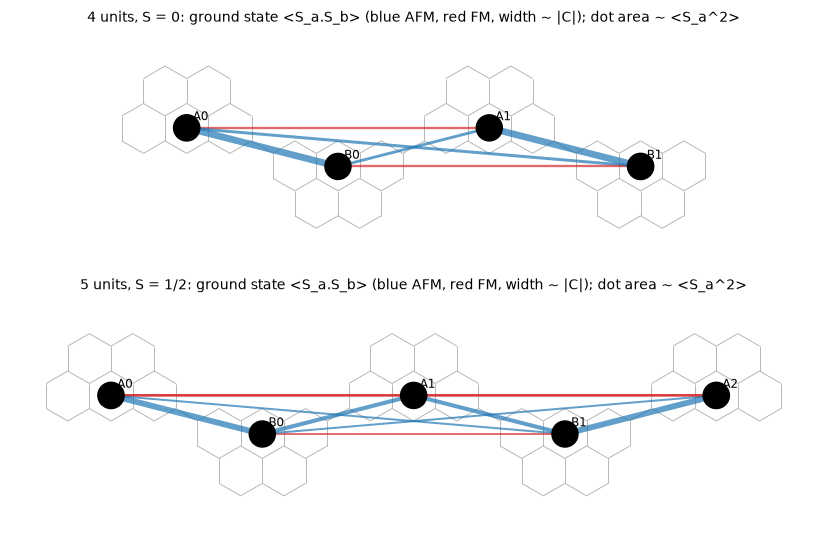

4 units: n_a = [1. 1. 1. 1.]  <S_a^2> = [0.7297 0.7196 0.7196 0.7297]
   nearest-neighbour <S_a.S_a+1> = [-0.6577 -0.2313 -0.6577]
5 units: n_a = [1. 1. 1. 1. 1.]  <S_a^2> = [0.732  0.7189 0.7229 0.7189 0.732 ]
   nearest-neighbour <S_a.S_a+1> = [-0.5571 -0.3616 -0.3616 -0.5571]


In [10]:
def site_pos(cl):
    # centroid of |w_a(x)|^2 of every cluster orbital (the GUI puts the marker on the atom named in the
    # model file instead; for the olympicene chain that atom is at the edge of the unit, so the lines
    # of different bonds would overlap)
    Wsq = cl["W"] ** 2
    return (Wsq.T @ cl["atom_xy"]) / Wsq.sum(axis=0)[:, None]

def cluster_atoms(cl):
    # atoms of the cells 0 .. ncells-1 kept in the drawing (a partial last cell shows whole units only)
    Na, nc = st.N, cl["ncells"]
    lo = 0 if cl["periodic"] else sorted(cl["w"])[0]
    rows = np.arange(-lo * Na, (nc - lo) * Na)
    return rows[tm.cluster_atoms_shown(cl).ravel()]

def draw_structure(ax, cl, color="0.7"):
    rows = cluster_atoms(cl)
    P = cl["atom_xy"][rows]
    ax.add_collection(LineCollection(P[bonds_of(P)], colors=color, linewidths=0.6, zorder=1))
    ax.set_aspect("equal"); ax.set_axis_off()
    pad = 2.0
    ax.set_xlim(P[:, 0].min() - pad, P[:, 0].max() + pad); ax.set_ylim(P[:, 1].min() - pad, P[:, 1].max() + pad)

def draw_correlations(ax, cl, res, state=0):
    draw_structure(ax, cl)
    C, pos = res["C"][state], site_pos(cl)
    for a in range(len(pos)):
        for b in range(a + 1, len(pos)):
            if abs(C[a, b]) > 0.02:
                ax.plot(*pos[[a, b]].T, color="tab:blue" if C[a, b] < 0 else "tab:red",
                        lw=0.5 + 6 * abs(C[a, b]), alpha=0.7, zorder=3)
    ax.scatter(*pos.T, s=400 * np.diag(C), color="k", zorder=4)
    for a, lab in enumerate(cl["labels"]):
        ax.annotate(lab, pos[a], xytext=(4, 5), textcoords="offset points", fontsize=8, zorder=5)

fig, axs = plt.subplots(2, 1, figsize=(9, 5))
for ax, (name, cl, res) in zip(axs, (("4 units, S = 0", cl4, res4), ("5 units, S = 1/2", cl5, res5))):
    draw_correlations(ax, cl, res)
    ax.set_title(f"{name}: ground state <S_a.S_b> (blue AFM, red FM, width ~ |C|); dot area ~ <S_a^2>")
plt.tight_layout(); plt.show()

for name, cl, res in (("4 units", cl4, res4), ("5 units", cl5, res5)):
    print(f"{name}: n_a =", np.round(res["n"][0], 4), " <S_a^2> =", np.round(np.diag(res["C"][0]), 4))
    print("   nearest-neighbour <S_a.S_a+1> =", np.round([res["C"][0][a, a + 1] for a in range(len(cl["T"]) - 1)], 4))

Each unit carries almost a full moment ($\langle\mathbf S^2\rangle\approx0.72$ to $0.73$ instead of $0.75$). Neighbours are antiparallel, with the strongest correlation on the end bonds (typical of short open Heisenberg chains). In the odd chain the unpaired spin is shared by the whole chain; a direct measure of this is the elastic weight of section 8.

## 8. Spin-flip transitions: the weight $W$ and the selection rules

**Physics.** A tunnelling electron can exchange its spin with the molecule. To lowest order (cotunnelling through an exchange coupling $J_\mathrm{tip}\,\mathbf S_v\cdot\boldsymbol\sigma$ at the tip position $v$), the inelastic channel $0\to f$ opens when $\lvert eV\rvert>E_f-E_0$, and for an **unpolarised tip at zero magnetic field** the height of the conductance step is

$$W_f(v)=\frac1{g_0}\sum_{M_0}\sum_{M_f}\sum_{a=x,y,z}\left\lvert\langle f,M_f\vert S^a_v\vert0,M_0\rangle\right\rvert^2$$

(ground multiplet averaged over its $g_0$ members, final multiplet summed). See e.g. J. Fernández-Rossier, PRL **102**, 256802 (2009), and M. Ternes, New J. Phys. **17**, 063016 (2015). Panel 7 computes exactly this quantity. The prefactor (tip density of states, $J_\mathrm{tip}^2$) is common to all steps and is not included.

**The operators.** With $S^z_{ab}=\frac12\left(c^\dagger_{a\uparrow}c_{b\uparrow}-c^\dagger_{a\downarrow}c_{b\downarrow}\right)$, $S^+_{ab}=c^\dagger_{a\uparrow}c_{b\downarrow}$, $S^-_{ab}=c^\dagger_{a\downarrow}c_{b\uparrow}$:

* on a reduced site $i$: $S^q_i=S^q_{ii}$;
* on an orbital $v$ (weights $v_a$ on the sites): $S^q_v=\sum_{ab}v_av_b\,S^q_{ab}$. For a tip on carbon $\mathbf x$, $v_a=w_a(\mathbf x)$: this is the spin density on atom $\mathbf x$ restricted to the model bands, $S^q_\mathbf{x}=\sum_{ab}w_a(\mathbf x)w_b(\mathbf x)S^q_{ab}$.

**From $x,y,z$ to $z,\pm$.** With $S^x=\frac12(S^++S^-)$ and $S^y=\frac1{2i}(S^+-S^-)$,

$$\lvert\langle f\vert S^x\vert g\rangle\rvert^2+\lvert\langle f\vert S^y\vert g\rangle\rvert^2=\tfrac12\left(\lvert\langle f\vert S^+\vert g\rangle\rvert^2+\lvert\langle f\vert S^-\vert g\rangle\rvert^2\right).$$

In a basis of definite $M_f$, $S^z$ reaches $M_f=M_0$, $S^+$ reaches $M_0+1$ and $S^-$ reaches $M_0-1$. The ED gives only the member $\lvert f\rangle$ with $M_f=M_0$ (same sector). The other two members are built as $\lvert f_\pm\rangle=S^\pm_\mathrm{tot}\lvert f\rangle/\lVert S^\pm_\mathrm{tot}f\rVert$, where $\lVert S^\pm_\mathrm{tot}f\rVert^2=S_f(S_f+1)-M_0(M_0\pm1)$ is either 0 (the member does not exist) or at least 2. A squared norm below $10^{-6}$ is treated as zero (no member). Then

$$\boxed{W_f(v)=\left(v^T\tau^z v\right)^2+\tfrac12\left(v^T\tau^+v\right)^2+\tfrac12\left(v^T\tau^-v\right)^2},\qquad \tau^q_{ab}=\langle f_q\vert S^q_{ab}\vert 0\rangle,\ f_z=f.$$

The matrices $\tau^q$ are the *transition spin densities* (`transition_amplitudes`), computed once per transition. With them the weight at any tip position costs only a matrix product (`spin_flip_weight`).

**Why one ground member is enough.** $\mathbf S_v$ is a vector (rank-1) operator. By the Wigner-Eckart theorem $\sum_{a,M_f}\lvert\langle f M_f\vert S^a_v\vert0M_0\rangle\rvert^2$ does not depend on $M_0$, so using the member in the computed sector is exact. The code still averages over the states of level 0 in the sector (relevant when level 0 has a degeneracy other than the spin one).

**Selection rules.** A rank-1 operator connects $S_0$ to $S_f\in\{S_0-1,S_0,S_0+1\}$, and never $0\to0$. The table flags this as `rule yes/no`. Forbidden transitions have $W=0$ exactly, not just small.

**Sum rule.** Summing over **all** final levels, including the ground level itself ($f=0$, the elastic term),

$$\sum_f W_f(i)=\langle0\vert\mathbf S_i\cdot\mathbf S_i\vert0\rangle=\langle\mathbf S_i^2\rangle .$$

For a singlet ground state the elastic term vanishes. For a doublet ($S=\frac12$) a large part of $\langle\mathbf S_i^2\rangle$ is elastic (spin flips inside the ground doublet, at zero energy). This is the channel of the Kondo effect, which lowest-order IETS does not describe (section 16).

**Per-site weights (`level_weights`)** are the $W_f(i)$ for $v=e_i$, for every level, used for the orange dots of the spectrum (area $\propto\sum_iW_f(i)$) and for the table.

In [11]:
# 1) the dimer: all spin-flip weight of a site goes to the triplet, W_1 = (3/8)(1 + U/(2R)) = <S_1^2>
lev_d, lw_d = tm.level_weights(res_d)
print("dimer: W_i per level:\n", lw_d, "\n analytic W_1(triplet) = (3/8)(1 + U/(2R)) =",
      round(3 / 8 * (1 + U_d / (2 * R)), 6), "  <S_1^2> =", round(res_d["C"][0][0, 0], 6))

# 2) brute-force check of W on the olympicene chains: average over ALL ground members (all S_z)
#    and sum over ALL members of the final multiplet, with S^x, S^y, S^z built explicitly
def brute_W(bf, dE, tol=1e-7):
    E0 = bf["E"][0]
    g = np.where(np.abs(bf["E"] - E0) < tol)[0]
    f = np.where(np.abs(bf["E"] - E0 - dE) < tol)[0]
    V = bf["V"]
    return np.array([sum(np.sum(np.abs(V[:, f].conj().T @ S[i] @ V[:, g]) ** 2) for S in (bf["Sx"], bf["Sy"], bf["Sz"]))
                     / len(g) for i in range(bf["Ns"])])

for name, res, bf in (("4 units", res4, bf4), ("5 units", res5, bf5)):
    print(f"\n{name}:")
    for li in range(0, 5):
        L = res["levels"][li]
        dE = res["E"][L[0]] - res["E"][0]
        print(f"  level {li} ({1e3 * dE:7.3f} meV, S = {res['S'][L[0]]:.1f}): W_i tbmany", np.round(res["lw"][li], 5),
              "| brute force", np.round(brute_W(bf, dE), 5))
    print("  sum rule: sum over all levels of W_i =", np.round(res["lw"].sum(axis=0), 6))
    print("            <S_i^2>                    =", np.round(np.diag(res["C"][0]), 6))
    print("  elastic part (level 0):", np.round(res["lw"][0], 4))

dimer: W_i per level:
 [[0.     0.    ]
 [0.7104 0.7104]
 [0.     0.    ]
 [0.     0.    ]] 
 analytic W_1(triplet) = (3/8)(1 + U/(2R)) = 0.71041   <S_1^2> = 0.71041

4 units:
  level 0 (  0.000 meV, S = 0.0): W_i tbmany [0. 0. 0. 0.] | brute force [0. 0. 0. 0.]
  level 1 ( 11.290 meV, S = 1.0): W_i tbmany [0.477  0.2945 0.2945 0.477 ] | brute force [0.477  0.2945 0.2945 0.477 ]
  level 2 ( 23.303 meV, S = 1.0): W_i tbmany [0.2439 0.2439 0.2439 0.2439] | brute force [0.2439 0.2439 0.2439 0.2439]
  level 3 ( 29.464 meV, S = 0.0): W_i tbmany [0. 0. 0. 0.] | brute force [0. 0. 0. 0.]
  level 4 ( 35.440 meV, S = 1.0): W_i tbmany [0.0083 0.1765 0.1765 0.0083] | brute force [0.0083 0.1765 0.1765 0.0083]
  sum rule: sum over all levels of W_i = [0.7297 0.7196 0.7196 0.7297]
            <S_i^2>                    = [0.7297 0.7196 0.7196 0.7297]
  elastic part (level 0): [0. 0. 0. 0.]

5 units:
  level 0 (  0.000 meV, S = 0.5): W_i tbmany [0.1911 0.0595 0.2299 0.0595 0.1911] | brute force [0.19

  level 1 ( 12.273 meV, S = 0.5): W_i tbmany [0.2254 0.0207 0.     0.0207 0.2254] | brute force [0.2254 0.0207 0.     0.0207 0.2254]
  level 2 ( 19.172 meV, S = 1.5): W_i tbmany [0.1601 0.3107 0.099  0.3107 0.1601] | brute force [0.1601 0.3107 0.099  0.3107 0.1601]
  level 3 ( 21.553 meV, S = 0.5): W_i tbmany [0.0782 0.0006 0.2597 0.0006 0.0782] | brute force [0.0782 0.0006 0.2597 0.0006 0.0782]
  level 4 ( 27.660 meV, S = 1.5): W_i tbmany [0.0739 0.2665 0.     0.2665 0.0739] | brute force [0.0739 0.2665 0.     0.2665 0.0739]
  sum rule: sum over all levels of W_i = [0.732  0.7189 0.7229 0.7189 0.732 ]
            <S_i^2>                    = [0.732  0.7189 0.7229 0.7189 0.732 ]
  elastic part (level 0): [0.1911 0.0595 0.2299 0.0595 0.1911]


Things to notice:

* the tbmany weights, built from one ground member and the $\pm$ members constructed with $S^\pm_\mathrm{tot}$, equal the brute-force ones (every $M_0$, every $M_f$, explicit $S^x,S^y,S^z$);
* forbidden transitions ($0\to0$, $\Delta S=2$) have exactly zero weight;
* the sum rule holds to machine precision because all states were computed. With the GUI default of 16 states the sum is partial;
* even chain: the elastic part is zero (singlet). Odd chain: about 0.2 of the 0.73 of the end units is elastic. The spin of the doublet lives mostly on the odd sites A0, A1, A2.

## 9. The transition table and the classification of a level

After "Run ED" the text output lists the transitions from the ground level (function `_sm_transition_table` of the GUI, reproduced below):

* `st`: index of the first state of the level (`+` if the level has more than one state in the sector);
* `E-E0`: excitation energy in meV;
* `S`: total spin of the final level;
* `W`: $\sum_iW_f(i)$, the spin-flip weight summed over the reduced sites;
* `rule`: $\lvert S_f-S_0\rvert\le1$ and not $0\to0$;
* `type`: from the change of the site charges $\Delta n_a$ and of the local moments $\Delta\langle\mathbf S_a^2\rangle$ between level 0 and level $f$:
  * `charge` if the charge moved, $\frac12\sum_a\lvert\Delta n_a\rvert\ge0.05$ (an electron hops to another site: doubly occupied or empty sites);
  * `spin*` if not, but some $\lvert\Delta\langle\mathbf S_a^2\rangle\rvert\ge0.05$ (the spin arrangement changes and the local moments too);
  * `spin` otherwise (a pure rearrangement of the local moments: a Heisenberg-like excitation);
* `strongest`: the two sites with the largest $W_f(i)$ (above 5% of the maximum).

Clicking a level runs `analyse_transition`. It gives the same numbers, plus the atom map, $\Delta C_{ab}$ and $\Delta S$, and prints them in the log (section 10).

In [12]:
def transition_table(res, cl, nmax=12):
    lev, lw, S, E = res["levels"], res["lw"], res["S"], res["E"]
    g0 = lev[0]; S0 = S[g0].mean()
    n0, D0 = res["n"][g0].mean(axis=0), np.diag(res["C"][g0].mean(axis=0))
    out = ["  st  E-E0 (meV)    S      W   rule  type    strongest"]
    for li in range(1, min(len(lev), nmax + 1)):
        g = lev[li]; Sf = S[g].mean()
        rule = abs(Sf - S0) < 1.01 and not (S0 < 0.25 and Sf < 0.25)
        kind = tm.classify(res["n"][g].mean(axis=0) - n0, np.diag(res["C"][g].mean(axis=0)) - D0)
        short = "charge" if kind.startswith("charge") else ("spin*" if "moments" in kind else "spin")
        wv = lw[li]
        top = ",".join(cl["labels"][i] for i in np.argsort(wv)[::-1][:2] if wv[i] > 0.05 * max(wv.max(), 1e-12))
        out.append(f"{g[0]:4d}{'+' if len(g) > 1 else ' '}{1e3 * (E[g[0]] - E[0]):10.4f} {Sf:4.1f} {wv.sum():6.3f}   "
                   f"{'yes' if rule else 'no '}  {short:6s}  " + (top if wv.sum() > 1e-4 else "-"))
    return "\n".join(out)

print("4 units (S = 0 ground state):\n" + transition_table(res4, cl4, 14))
print("\n5 units (S = 1/2 ground state):\n" + transition_table(res5, cl5, 14))

4 units (S = 0 ground state):
  st  E-E0 (meV)    S      W   rule  type    strongest
   1    11.2904  1.0  1.543   yes  spin    B1,A0
   2    23.3034  1.0  0.976   yes  spin    B0,A0
   3    29.4636  0.0  0.000   no   spin    -
   4    35.4395  1.0  0.370   yes  spin    A1,B0
   5    40.5696  2.0  0.000   no   spin    -
   6   486.6418  0.0  0.000   no   spin*   -
   7   494.8891  1.0  0.000   yes  spin*   -
   8   496.4140  0.0  0.000   no   spin*   -
   9   503.9046  1.0  0.006   yes  spin*   A1,B0
  10   548.0504  0.0  0.000   no   spin*   -
  11   556.6888  0.0  0.000   no   spin*   -
  12   556.6889  1.0  0.000   yes  spin*   -
  13   565.3166  1.0  0.001   yes  spin*   A0,B0
  14   594.3782  0.0  0.000   no   spin*   -

5 units (S = 1/2 ground state):
  st  E-E0 (meV)    S      W   rule  type    strongest
   1    12.2730  0.5  0.492   yes  spin    A2,A0
   2    19.1722  1.5  1.041   yes  spin    B0,B1
   3    21.5530  0.5  0.417   yes  spin    A1,A0
   4    27.6601  1.5  0.681   

Both chains show the two families of excitations of a Hubbard chain:

* **spin excitations** (tens of meV): the $\binom{N}{N/2}$ (even) or $\binom{N}{(N-1)/2}$ (odd) states of the spin manifold, which a Heisenberg model on the units reproduces (tab 4 fits it). For 4 units: 6 states (2 singlets, 3 triplets, 1 quintet). For 5 units: 10 states (5 doublets, 4 quartets, 1 sextet). Only $\Delta S=\pm1$ (and $0$ for $S_0=\frac12$) carry weight;
* **charge excitations** (about $U-$ bandwidth, here above 0.45 eV): states with a doubly occupied and an empty unit, with very small spin-flip weight. Here they are labelled `spin*`, not `charge`: in a chain with a mirror (or C2) symmetry every eigenstate has the same average charge on mirror-related sites, so the doublon and the holon are delocalised over symmetric positions and $\Delta n_a$ is zero on average. What changes is the local moment ($\langle\mathbf S_a^2\rangle$ drops, since a doubly occupied or empty unit has no moment). The label `charge` appears when the structure has no such symmetry, or with a different electron number.

The spectrum panel zooms on the spin manifold when the spin sites are ticked (their count gives the number of spin states $M$), if the next state is more than 3 times higher than the top of the manifold; it then prints "next state at ... (off scale)".

## 10. Maps of a spin excitation (click a level)

For the transition $0\to f$ the map panel shows three things:

1. **Orange image: the inelastic (spin-flip) map on the atoms**,

$$W_f(\mathbf x)=\left(\textstyle\sum_{ab}w_a(\mathbf x)\tau^z_{ab}w_b(\mathbf x)\right)^2+\tfrac12\left(\textstyle\sum_{ab}w_a\tau^+_{ab}w_b\right)^2+\tfrac12\left(\textstyle\sum_{ab}w_a\tau^-_{ab}w_b\right)^2 ,$$

   i.e. the step height of the IETS signal with the tip above atom $\mathbf x$, for all the carbons that the orbitals reach (`cl["atom_xy"]`, including the tails outside the drawn cells). The cross terms $a\neq b$ make it more than a sum of orbital densities: the transition spin density of neighbouring units can interfere. The image puts a Gaussian of width $\sigma=0.9$ Å on every atom, weighted by $W_f(\mathbf x)$, on a 0.1 Å grid (`tbcore.ldos_image`, the same routine as the dI/dV maps of tab 1). This mimics the lateral resolution of a $p_z$ orbital seen by the tip at constant height.
2. **Circles: the per-site weights** $W_f(i)$ (area $\propto W_f(i)$, and the value next to the label).
3. **Lines: the change of the spin correlations** $\Delta C_{ab}=C_{ab}(f)-C_{ab}(0)$ for $\lvert\Delta C_{ab}\rvert>0.02$: red if the bond becomes more ferromagnetic, blue if more antiferromagnetic. They show *which bonds are excited*, e.g. a singlet on a bond broken into a triplet.

level 1: W_i = [0.225 0.021 0.    0.021 0.225];  Delta C on the bonds A0-B0, B0-A1, A1-B1, B1-A2: [ 0.389 -0.043 -0.043  0.389]
level 2: W_i = [0.16  0.311 0.099 0.311 0.16 ];  Delta C on the bonds A0-B0, B0-A1, A1-B1, B1-A2: [ 0.565 -0.022 -0.022  0.565]
level 3: W_i = [0.078 0.001 0.26  0.001 0.078];  Delta C on the bonds A0-B0, B0-A1, A1-B1, B1-A2: [0.186 0.417 0.417 0.186]


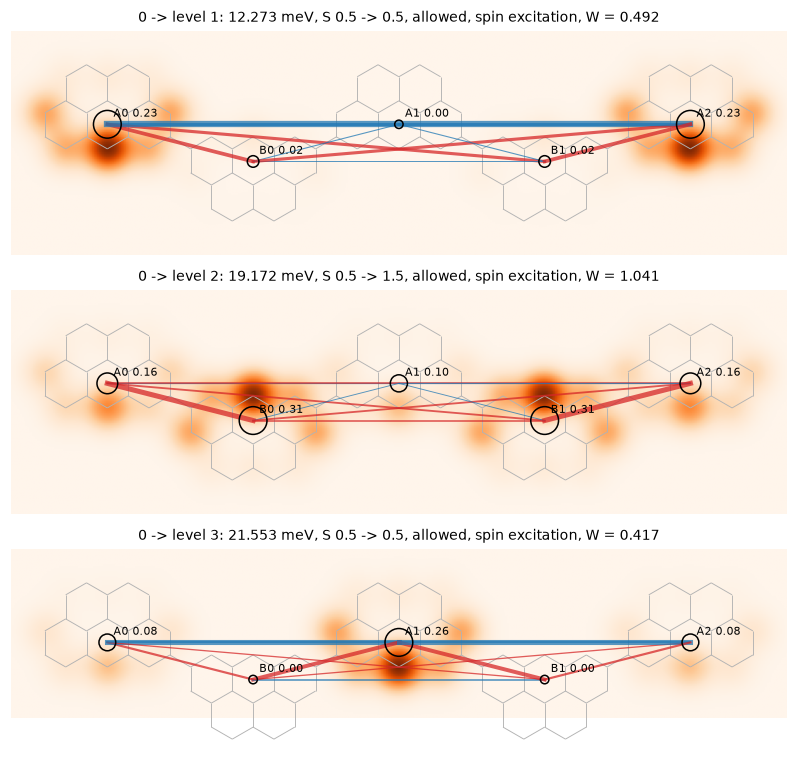

In [13]:
def map_image(ax, cl, vals, cmap):
    xy = cl["atom_xy"]
    keep = vals > 1e-3 * max(vals.max(), 1e-12)
    img, ext = tb.ldos_image(tb.Structure(xy[keep], ["C"] * int(keep.sum()), st.T), vals[keep], cells=(0,), sigma=0.9)
    ax.imshow(img, origin="lower", extent=ext, cmap=cmap, vmin=0, aspect="equal", zorder=0)

def draw_transition(ax, cl, res, level):
    a = tm.analyse_transition(res, res["levels"][level], W=cl["W"])
    draw_structure(ax, cl)
    map_image(ax, cl, a["w_atom"], "Oranges")
    pos, ws = site_pos(cl), a["w_site"]
    for i in range(len(pos)):
        for j in range(i + 1, len(pos)):
            if abs(a["dC"][i, j]) > 0.02:
                ax.plot(*pos[[i, j]].T, color="tab:red" if a["dC"][i, j] > 0 else "tab:blue",
                        lw=0.5 + 5 * abs(a["dC"][i, j]), alpha=0.75, zorder=3)
    ax.scatter(*pos.T, s=30 + 300 * ws / max(ws.max(), 1e-12), facecolors="none", edgecolors="k", lw=1.0, zorder=4)
    for i, lab in enumerate(cl["labels"]):
        ax.annotate(f"{lab} {ws[i]:.2f}", pos[i], xytext=(4, 5), textcoords="offset points", fontsize=7, zorder=5)
    ax.set_title(f"0 -> level {level}: {1e3 * a['dE']:.3f} meV, S {a['S0']:.1f} -> {a['Sf']:.1f}, "
                 f"{'allowed' if a['allowed'] else 'forbidden'}, {a['kind']}, W = {a['total']:.3f}")
    return a

fig, axs = plt.subplots(3, 1, figsize=(9, 7.2))
for ax, lv in zip(axs, (1, 2, 3)):
    a = draw_transition(ax, cl5, res5, lv)
    print(f"level {lv}: W_i = {np.round(a['w_site'], 3)};  Delta C on the bonds A0-B0, B0-A1, A1-B1, B1-A2:",
          np.round([a["dC"][i, i + 1] for i in range(4)], 3))
plt.tight_layout(); plt.show()

Reading the three lowest excitations of the 5-unit chain:

* **level 1** ($S=\frac12\to\frac12$, about 12 meV): the weight is almost only on the two end units, and the end bonds A0-B0 and B1-A2 lose most of their antiferromagnetic correlation ($\Delta C\approx+0.4$) while the inner bonds hardly change. It is the excitation of the end spins;
* **level 2** ($\frac12\to\frac32$, about 19 meV): the first quartet. Again the end bonds change most ($\Delta C\approx+0.57$), but the weight is largest on B0 and B1, the units next to the ends;
* **level 3** ($\frac12\to\frac12$, about 22 meV): now the inner bonds change most ($\Delta C\approx+0.42$) and the weight is on the central unit A1.

None of them flips "one spin". They are collective standing waves of the chain, so the weight is spread over several units (this was the question in the previous message). On each unit the atom map has the shape of $\lvert w_i(\mathbf x)\rvert^2$, the SOMO of the unit.

## 11. The inelastic tip spectrum (IETS panel)

With the tip on an orbital $v$ (a reduced site selected in "tip on site", or an atom clicked on the map, $v_a=w_a(\mathbf x)$) the lower-right panel shows

$$\frac{dI}{dV}\Big\vert_\mathrm{inel}(V)=\sum_{f\neq0}W_f(v)\;\Theta_w\!\left(\lvert eV\rvert-\Delta E_f\right),\qquad\Theta_w(x)=\tfrac12\left[1+\tanh\frac{x}{2w}\right],$$

a step of height $W_f(v)$ at $\lvert eV\rvert=\Delta E_f=E_f-E_0$ for both polarities (symmetric, as for an unpolarised tip). The steps are smoothed with width $w$ ("inel. (meV)"; `auto` = 3% of the smallest excitation energy), a stand-in for thermal and instrumental broadening. The weights come from the stored transition densities (`inelastic_amplitudes`, then `inelastic_weights_at`), so moving the tip is instantaneous. The elastic term $f=0$ is not plotted: it adds a constant background (and, for $S_0\geq\frac12$, the Kondo channel). The bias range is $\pm1.4\times$ the top of the spin manifold (or of the computed levels).

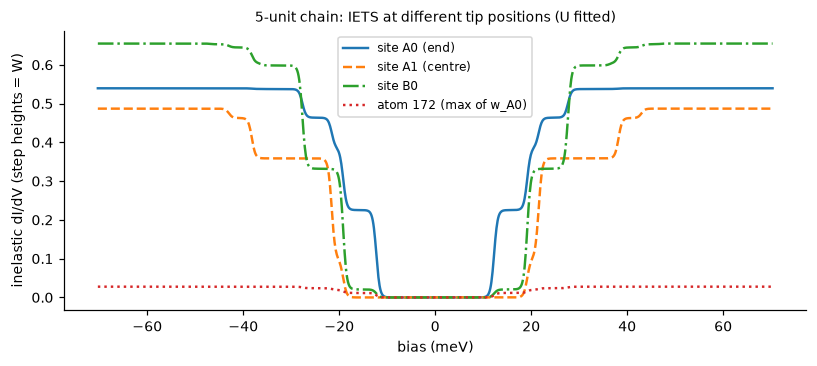

norm of the tip orbital on the atom: sum_a w_a(x)^2 = 0.227 (the fraction of the model bands on that carbon)


In [14]:
def iets_curve(res, v, width=None, top=None):
    taus, ng = res["taus"]
    Wl = tm.inelastic_weights_at(taus, ng, v)[1:]
    E = 1e3 * (res["E"] - res["E"][0])
    dE = np.array([E[L[0]] for L in res["levels"]])[1:]
    wi = 0.03 * dE[dE > 1e-9].min() if width is None else width
    top = dE.max() if top is None else top
    bias = np.linspace(-1.4 * top, 1.4 * top, 1201)
    return bias, tm.iets_dIdV(dE, Wl, bias, wi), dE, Wl

top5 = 1e3 * (res5["E"][9] - res5["E"][0])     # top of the 10 spin states of 5 spins-1/2
tips = [("site A0 (end)", np.eye(5)[0]), ("site A1 (centre)", np.eye(5)[2]), ("site B0", np.eye(5)[1])]
xA0 = int(np.argmax(cl5["W"][:, 0] ** 2))        # the atom where orbital A0 is largest
tips.append((f"atom {xA0} (max of w_A0)", cl5["W"][xA0]))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for (name, v), ls in zip(tips, ("-", "--", "-.", ":")):
    bias, g, dE, Wl = iets_curve(res5, v, top=top5)
    ax.plot(bias, g, ls=ls, lw=1.6, label=name)
ax.set_xlabel("bias (meV)"); ax.set_ylabel("inelastic dI/dV (step heights = W)")
ax.set_title("5-unit chain: IETS at different tip positions (U fitted)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("norm of the tip orbital on the atom: sum_a w_a(x)^2 =", round(float(np.sum(cl5["W"][xA0] ** 2)), 4),
      "(the fraction of the model bands on that carbon)")

The first step (level 1, about 12 meV) is strong at the ends and absent in the centre: this is how the end-spin excitation would be recognised in experiment. On an atom the steps have the same energies, but $S_\mathbf x$ contains the orbital amplitudes twice, so the step heights are reduced by roughly $\left(\sum_a w_a(\mathbf x)^2\right)^2$ (about 0.05 on the brightest carbon here) and shaped by the interference of neighbouring orbitals. Only the relative heights at one tip position are meaningful.

**Dependence on $U$.** All spin excitation energies scale roughly like $J\approx4t^2/U$. The next cell repeats the ED with the projected $U$ and with the fitted $U$: the choice of box 1 changes the energy scale but hardly the pattern of weights.

In [15]:
for name, Uv in (("projected", U_proj), ("fitted", U_fit)):
    clx = panel7_cluster(3, Uv, keep_last=["A"])
    rx = panel7_ed(clx, 5, nstates=16)
    E = 1e3 * (rx["E"] - rx["E"][0])
    print(f"U {name} = {Uv[0]:.3f} eV: 4t^2/U = {1e3 * 4 * pv['t'] ** 2 / Uv[0]:.2f} meV;",
          "first levels (meV):", np.round([E[L[0]] for L in rx["levels"][1:5]], 2),
          " W at A0:", np.round(rx["lw"][1:5, 0], 3))

U projected = 0.421 eV: 4t^2/U = 23.74 meV; first levels (meV): [16.04 25.18 28.16 36.26]  W at A0: [0.222 0.156 0.078 0.072]
U fitted = 0.566 eV: 4t^2/U = 17.66 meV; first levels (meV): [12.27 19.17 21.55 27.66]  W at A0: [0.225 0.16  0.078 0.074]


## 12. Charge excitations: adding and removing one electron (box 3)

"Compute charge excitations" diagonalises the sectors with one electron more and one less (`charge_excitations`) and computes the **Dyson amplitudes**

$$d^{+}_{f\sigma}(a)=\langle f^{N+1}\vert c^\dagger_{a\sigma}\vert0\rangle,\qquad d^{-}_{f\sigma}(a)=\langle f^{N-1}\vert c_{a\sigma}\vert0\rangle .$$

For a tip on the orbital $v$ ($c_{v\sigma}=\sum_av_ac_{a\sigma}$) the one-particle spectral function in Lehmann form is

$$A_v(\omega)=\sum_{\sigma}\sum_f\Big\lvert\sum_a v_a\,d^{+}_{f\sigma}(a)\Big\rvert^2\delta\!\left(\omega-\omega^{+}_f\right)+\sum_\sigma\sum_f\Big\lvert\sum_a v_a\,d^{-}_{f\sigma}(a)\Big\rvert^2\delta\!\left(\omega-\omega^{-}_f\right),$$

$$\omega^{+}_f=E_f(N+1)-E_0(N)\ \ (\text{addition, empty states, positive bias}),\qquad\omega^{-}_f=E_0(N)-E_f(N-1)\ \ (\text{removal, filled states, negative bias}),$$

averaged over the states of the ground level. The energies are measured from $E_F$ because $T$ has $\varepsilon_i-E_F$ on the diagonal and the interaction is in particle-hole form. In the Tersoff-Hamann picture the elastic $dI/dV$ at bias $V$ is proportional to $A_v(eV)$.

**Spins.** If $N_\uparrow=N_\downarrow$ (even $N$, $S_z=0$) the two spins are equivalent: only $\sigma=\uparrow$ is computed and the weight is doubled (`mult = 2`). Otherwise both spins are computed: adding $\uparrow$ reaches $S_z+\frac12$, adding $\downarrow$ reaches $S_z-\frac12$. Summed over both, the result does not depend on the ground member (Wigner-Eckart again, $c^\dagger_\sigma$ being a spinor).

**Only the lowest states.** Each of the $N\pm1$ sectors gives its lowest `N-1, N+1 states / sector` eigenstates (default 12, Lanczos). The spectrum is therefore complete near the gap only: the lowest additions and the highest removals, i.e. the peaks closest to $E_F$. The log prints the range covered.

**Sum rules** (all states): for a normalised $v$,

$$\sum_f(\text{removal weights, spin }\sigma)=\langle n_{v\sigma}\rangle,\qquad\sum_f(\text{addition weights, spin }\sigma)=1-\langle n_{v\sigma}\rangle .$$

For $v=w(\mathbf x)$ the total is $\sum_aw_a(\mathbf x)^2$ instead of 1. **Charge gap** (printed in the log): $\Delta_c=E_0(N+1)+E_0(N-1)-2E_0(N)=\min\omega^+-\max\omega^-$.

### 12.1 Checks: the dimer, brute force, sum rules and $U=0$

Dimer at half filling, $R=\frac12\sqrt{U^2+16t^2}$: the peaks are at $\omega=\pm(R-t)$ with weight $\frac12(1+2t/R)$ and at $\pm(R+t)$ with weight $\frac12(1-2t/R)$ on each site (both spins summed). At $U=0$ ($R=2t$) this reduces to one peak at the antibonding level $+t$ and one at the bonding level $-t$, with weight 1 each.

In [16]:
ch_d = tm.charge_excitations(res_d, dimer_cluster(t_d, U_d), nstates=10)
Ew, Wt, kd = tm.tip_peaks(ch_d, [1.0, 0.0])
print("dimer peaks (eV):", np.round(Ew, 5), kd, "\n      weights    :", np.round(Wt, 5))
print(f"analytic: +-(R-t) = +-{R - t_d:.5f} (weight {0.5 * (1 + 2 * t_d / R):.5f}),  "
      f"+-(R+t) = +-{R + t_d:.5f} (weight {0.5 * (1 - 2 * t_d / R):.5f})")

# olympicene chains: all N+-1 states, sum rules and brute force
def brute_addition(cl, bf, nel, site):
    g = np.where(np.abs(bf["E"] - bf["E"][0]) < 1e-8)[0]
    bp = brute_force(cl["T"], cl["U_site"], nel + 1)
    A = 0
    for cs in (bf["cu"], bf["cd"]):
        op = cs[site].T.toarray()[np.ix_(bp["idx"], bf["idx"])]
        A = A + (np.abs(bp["V"].conj().T @ op @ bf["V"][:, g]) ** 2).mean(axis=1)
    return bp["E"] - bf["E"][0], A

grid = np.linspace(-0.1, 0.9, 3000)
for name, cl, res, bf, nel in (("4 units", cl4, res4, bf4, 4), ("5 units", cl5, res5, bf5, 5)):
    ch = tm.charge_excitations(res, cl, nstates=10 ** 6)
    Ew, Wt, kd = tm.tip_peaks(ch, np.eye(len(cl["T"]))[0])
    wb, Ab = brute_addition(cl, bf, nel, 0)
    diff = np.abs(tm.broadened(Ew[kd == "add"], Wt[kd == "add"], grid, 0.01) - tm.broadened(wb, Ab, grid, 0.01)).max()
    add = np.concatenate([c["w"] for c in ch if c["kind"] == "add"])
    rem = np.concatenate([c["w"] for c in ch if c["kind"] == "remove"])
    print(f"\n{name}: sectors", [(c["kind"], "up" if c["spin"] == 0 else "down", c["dim"], "mult", c["mult"]) for c in ch])
    print(f"  site A0: removal sum {Wt[kd == 'remove'].sum():.6f} = <n_A0> = {res['n'][0][0]:.6f};"
          f" addition sum {Wt[kd == 'add'].sum():.6f} = 2 - <n_A0>")
    print(f"  addition spectrum at A0 vs brute force: max difference {diff:.1e}")
    print(f"  charge gap {add.min() - rem.max():.4f} eV (lowest addition {add.min():+.4f}, highest removal {rem.max():+.4f})")

# U = 0: peaks at the single-particle levels of T
cl0 = panel7_cluster(3, [0.0, 0.0], keep_last=["A"])
r0 = panel7_ed(cl0, 5, nstates=10 ** 6)
ch0 = tm.charge_excitations(r0, cl0, nstates=10 ** 6)
Ew0, Wt0, kd0 = tm.tip_peaks(ch0, np.eye(5)[0])
print("\nU = 0, 5 units: single-particle levels of T (eV):", np.round(np.linalg.eigvalsh(cl0["T"]), 4))
print("               peaks with weight at A0 (eV)     :", np.round(np.unique(np.round(Ew0[Wt0 > 1e-8], 6)), 4))

dimer peaks (eV): [ 0.1736  0.2736 -0.1736 -0.2736] ['add' 'add' 'remove' 'remove'] 
      weights    : [0.7236 0.2764 0.7236 0.2764]
analytic: +-(R-t) = +-0.17361 (weight 0.72361),  +-(R+t) = +-0.27361 (weight 0.27639)



4 units: sectors [('add', 'up', 24, 'mult', 2), ('remove', 'up', 24, 'mult', 2)]
  site A0: removal sum 0.999999 = <n_A0> = 0.999999; addition sum 1.000001 = 2 - <n_A0>
  addition spectrum at A0 vs brute force: max difference 1.3e-12
  charge gap 0.4422 eV (lowest addition +0.2211, highest removal -0.2210)



5 units: sectors [('add', 'up', 50, 'mult', 1), ('add', 'down', 100, 'mult', 1), ('remove', 'up', 100, 'mult', 1), ('remove', 'down', 50, 'mult', 1)]
  site A0: removal sum 0.999998 = <n_A0> = 0.999998; addition sum 1.000002 = 2 - <n_A0>
  addition spectrum at A0 vs brute force: max difference 3.9e-13
  charge gap 0.4205 eV (lowest addition +0.2103, highest removal -0.2102)



U = 0, 5 units: single-particle levels of T (eV): [-0.0864 -0.0499  0.      0.0501  0.0867]
               peaks with weight at A0 (eV)     : [-0.0864 -0.0499  0.      0.0501  0.0867]


At $U=0$ the addition and removal peaks sit exactly at the single-particle levels of $T$ (the level at 0 is the half-filled SOMO of the odd chain, seen in both addition and removal). With $U$ they move apart by about $U$ minus the kinetic energy gained by the extra electron or hole: the charge gap of the chains, about 0.44 eV, is smaller than $U=0.57$ eV.

## 13. The tip spectrum panel (lower left)

For the tip orbital $v$ (site or atom) the panel draws

* sticks at every $\omega_f^\pm$ with height $\text{weight}/(\sqrt{2\pi}\,w_c)$ (the maximum of its Gaussian), blue for removal, red for addition;
* the black curve $\sum_f\text{weight}_f\,g_{w_c}(\omega-\omega_f)$, a Gaussian broadening of width $w_c$ = "width (eV)" (default 0.02 eV) on a grid from the lowest to the highest computed peak $\pm5w_c$;
* a dashed line at $E_F$.

Clicking near a peak selects the closest **bright** state (total weight $\sum_a\lvert d_f(a)\rvert^2\ge10^{-4}$, averaged over the ground level). Dark states, e.g. $N+1$ states of total spin $S_0+\frac32$ that one electron cannot reach from the ground state, are skipped. The map panel then shows its Dyson map (section 14).

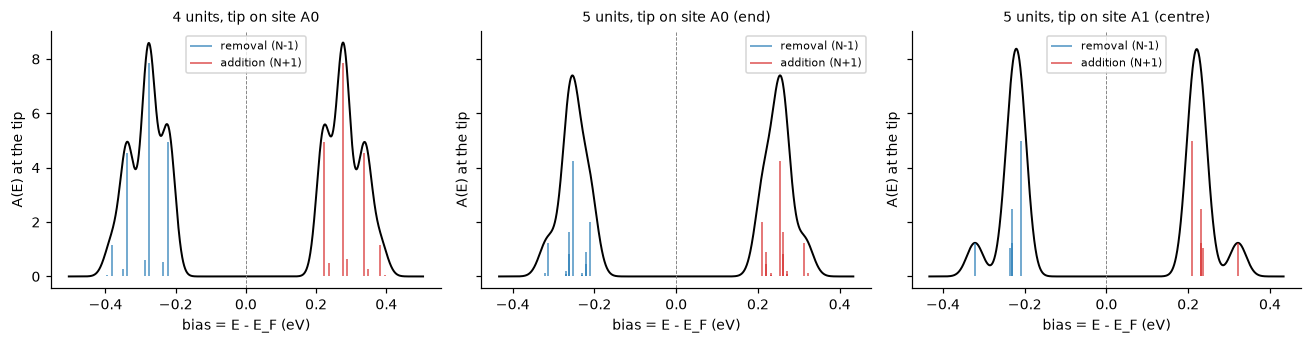

5 units, 12 states per sector: covered from -0.333 to +0.333 eV

4 units, sites ['A0', 'B0', 'A1', 'B1']
  remove -0.2210 eV  (up sector, state 0):  weight per site [0.249 0.231 0.231 0.249]  total 0.959
  remove -0.2352 eV  (up sector, state 1):  weight per site [0.026 0.303 0.303 0.026]  total 0.658
  remove -0.2765 eV  (up sector, state 3):  weight per site [0.393 0.085 0.085 0.393]  total 0.956
  add    +0.2211 eV  (up sector, state 0):  weight per site [0.249 0.231 0.231 0.249]  total 0.958
  add    +0.2354 eV  (up sector, state 1):  weight per site [0.026 0.303 0.303 0.026]  total 0.657
  add    +0.2767 eV  (up sector, state 3):  weight per site [0.394 0.085 0.085 0.394]  total 0.958
5 units, sites ['A0', 'B0', 'A1', 'B1', 'A2']
  remove -0.2102 eV  (up sector, state 0):  weight per site [0.1   0.001 0.251 0.001 0.1  ]  total 0.453
  remove -0.2202 eV  (up sector, state 1):  weight per site [0.023 0.089 0.    0.089 0.023]  total 0.223
  remove -0.2202 eV  (down sector, state 0): 

In [17]:
ch5 = tm.charge_excitations(res5, cl5, nstates=12)           # GUI default: 12 states per sector
ch4 = tm.charge_excitations(res4, cl4, nstates=12)

def tip_spectrum(ax, ch, v, name, wc=0.02):
    Ep, Wp, kind = tm.tip_peaks(ch, v)
    gr = np.linspace(Ep.min() - 5 * wc, Ep.max() + 5 * wc, 1500)
    ax.plot(gr, tm.broadened(Ep, Wp, gr, wc), color="k", lw=1.3)
    for kd_, col, lab in (("remove", "tab:blue", "removal (N-1)"), ("add", "tab:red", "addition (N+1)")):
        s = kind == kd_
        ax.vlines(Ep[s], 0, Wp[s] / (np.sqrt(2 * np.pi) * wc), color=col, lw=1.0, alpha=0.8, label=lab)
    ax.axvline(0, color="0.5", lw=0.6, ls="--")
    ax.set_xlabel("bias = E - E_F (eV)"); ax.set_ylabel("A(E) at the tip"); ax.set_title(name)
    ax.legend(fontsize=7)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
tip_spectrum(axs[0], ch4, np.eye(4)[0], "4 units, tip on site A0")
tip_spectrum(axs[1], ch5, np.eye(5)[0], "5 units, tip on site A0 (end)")
tip_spectrum(axs[2], ch5, np.eye(5)[2], "5 units, tip on site A1 (centre)")
plt.tight_layout(); plt.show()
add = np.concatenate([c["w"] for c in ch5 if c["kind"] == "add"]); rem = np.concatenate([c["w"] for c in ch5 if c["kind"] == "remove"])
print(f"5 units, 12 states per sector: covered from {rem.min():+.3f} to {add.max():+.3f} eV")

def peaks_near_EF(ch, cl, n=3):
    # the n bright peaks closest to E_F on each side, with their weight on every site
    for kind in ("remove", "add"):
        rows = []
        for c in ch:
            if c["kind"] != kind:
                continue
            ws = c["mult"] * (c["D"] ** 2).mean(axis=0)            # (states, sites)
            rows += [(wv, c["spin"], j, ws[j]) for j, wv in enumerate(c["w"]) if ws[j].sum() > 1e-4]
        for wv, s_, j, ws in sorted(rows, key=lambda x: abs(x[0]))[:n]:
            print(f"  {kind:6s} {wv:+.4f} eV  ({'up' if s_ == 0 else 'down'} sector, state {j}):  weight per site",
                  np.round(ws, 3), f" total {ws.sum():.3f}")
print("\n4 units, sites", cl4["labels"]); peaks_near_EF(ch4, cl4)
print("5 units, sites", cl5["labels"]); peaks_near_EF(ch5, cl5)

The peaks form two groups at about $\pm U/2$ (the lower and upper Hubbard bands of the units), each spread by the hopping into a band of a few $t$. For a half-filled unit the total weight of each group is 1 (the sum rules above). The site pattern of the peaks closest to $E_F$ differs between the two chains:

* 4 units (singlet): the first removal and addition peaks are spread over all four units;
* 5 units (doublet): the peaks closest to $E_F$ ($\pm0.21$ eV) sit on the odd units A0, A1, A2, with the largest weight in the centre. They correspond to removing the unpaired electron, or adding its partner. This is the correlated version of the SOMO of an odd chain, which at $U=0$ is $(1,0,-1,0,1)/\sqrt3$ on A0 B0 A1 B1 A2. The next peaks ($\pm0.22$ eV) are on B0 and B1.

With a tip on a site ("tip on site") these patterns show up directly as different spectra at the ends and in the centre.

## 14. Dyson maps (click a peak)

The atom-resolved amplitude of a charge excitation is the **Dyson orbital**

$$\phi_{f\sigma}(\mathbf x)=\sum_a w_a(\mathbf x)\,d_{f\sigma}(a),$$

and the map shown is

$$\rho_f(\mathbf x)=\text{mult}\times\frac1{g_0}\sum_{g\in\text{level }0}\sum_\sigma\lvert\phi_{f\sigma}(\mathbf x)\rvert^2$$

(`dyson_map`), drawn with the same Gaussian spots (0.9 Å) in purple. For an odd electron number both spin sectors are computed and a state is identified by (kind, spin sector, index); the map uses the sector of the clicked peak. This is the constant-height STM map at the bias of that peak, if that peak alone contributes. At $U=0$ it is the square of a single-particle orbital. With interactions it is the orbital into which the extra electron (or hole) goes, *given the correlated ground state*. For example, adding an electron to a unit that already has one (it must pair it into a singlet) gives a different map from the $U=0$ LUMO.

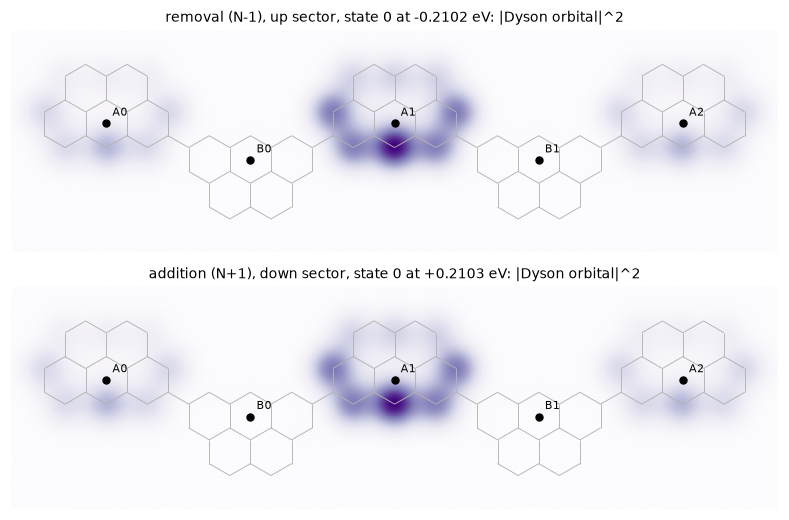

In [18]:
def dyson_map_plot(ax, cl, ch, kind, index, spin):
    vals = tm.dyson_map(ch, kind, index, cl["W"], spin=spin)
    draw_structure(ax, cl)
    map_image(ax, cl, vals, "Purples")
    pos = site_pos(cl)
    ax.scatter(*pos.T, s=20, color="k", zorder=4)
    for a, lab in enumerate(cl["labels"]):
        ax.annotate(lab, pos[a], xytext=(4, 5), textcoords="offset points", fontsize=7, zorder=5)
    w = [c["w"][index] for c in ch if c["kind"] == kind and c["spin"] == spin][0]
    ax.set_title(f"{'addition (N+1)' if kind == 'add' else 'removal (N-1)'}, {'up' if spin == 0 else 'down'} sector, "
                 f"state {index} at {w:+.4f} eV: |Dyson orbital|^2")

def closest_bright(ch, kind):
    # the bright state closest to E_F among all sectors of that kind: (index in its sector, spin sector)
    best = None
    for c in ch:
        if c["kind"] != kind:
            continue
        norm = (c["D"] ** 2).sum(axis=2).mean(axis=0)
        for j, wv in enumerate(c["w"]):
            if norm[j] >= 1e-4 and (best is None or abs(wv) < abs(best[2])):
                best = (j, c["spin"], wv)
    return best[:2]

fig, axs = plt.subplots(2, 1, figsize=(9, 4.8))
dyson_map_plot(axs[0], cl5, ch5, "remove", *closest_bright(ch5, "remove"))
dyson_map_plot(axs[1], cl5, ch5, "add", *closest_bright(ch5, "add"))
plt.tight_layout(); plt.show()

In the 5-unit chain the highest removal (up sector: the unpaired up electron is taken out) and the lowest addition (down sector: its partner is added) have the same map, concentrated on the centre unit A1 with some weight on the ends A0 and A2. This is the particle-hole symmetry of the model with $\varepsilon_i=E_F$. Inside each unit the map has the shape of the SOMO $\lvert w_i(\mathbf x)\rvert^2$. Clicking the other peaks in the GUI shows the B-centred states at $\pm0.22$ eV and so on.

## 15. Second example: sites with and without a local moment (goblet chain)

In `real_goblet_chain.eff` the four sites per cell are two "heads" (Tu, Td: localised radical orbitals, $U_i\approx0.42$ eV) and two backbone orbitals (Bu, Bd: more spread, $U_i\approx0.25$ eV, strongly bonded to each other, $t_B\approx-0.2$ eV). Panel 7 treats all of them identically: the "spin" ticks of box 1 only choose the zoom of the spectrum. The ED shows which sites carry moments:

* heads: $\langle\mathbf S^2\rangle\approx0.75$, free moments weakly coupled through the backbone (spin manifold of $\binom42=6$ states below 0.1 meV);
* backbone: $\langle\mathbf S^2\rangle\approx0.45$ to $0.48$, close to the uncorrelated $\frac38$ of a covalent bond. Its spin-flip weight appears only at 180 meV and above, in `spin*` and `charge` excitations of the Bu-Bd bond.

This is the sum rule of section 8 at work: every site has $\sum_fW_f(i)=\langle\mathbf S_i^2\rangle$, but a site without a local moment puts its weight at the energy of its bond (singlet-triplet of the bond, of order $t_B$), not in the low-energy spin manifold.

goblet chain, 2 cells: sites ['Tu0', 'Td0', 'Bu0', 'Bd0', 'Tu1', 'Td1', 'Bu1', 'Bd1'], dimension 4900, 60 states in 1.0 s
U_i (eV): {'Tu': 0.423, 'Td': 0.423, 'Bu': 0.248, 'Bd': 0.248}  fitted: {'eT': 0.4193, 'eB': 0.476, 'tB': -0.2011, 'tau': -0.022}
<S_a^2>: [0.747 0.748 0.482 0.455 0.748 0.747 0.455 0.482]

level   E-E0 (meV)   S   W heads  W backbone
    1        0.026  1.0    1.7758     0.0003
    2        0.056  1.0    0.9050     0.0000
    3        0.078  0.0    0.0000     0.0000
    4        0.078  1.0    0.3012     0.0000
    5        0.083  2.0    0.0000     0.0000
    6      178.683  1.0    0.0000     0.0027
    9      182.168  1.0    0.0002     0.0907
   14      185.274  1.0    0.0000     0.3648
   16      186.780  1.0    0.0000     0.2417
   58      358.633  1.0    0.0000     0.5467


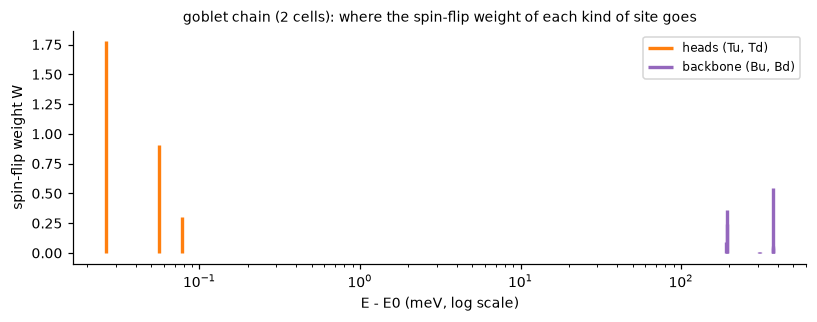

In [19]:
st_g = tb.load_structure(os.path.join(EX, "real_goblet_chain.hex"))
m_g = tb.parse_eff(open(os.path.join(EX, "real_goblet_chain.eff")).read(), st_g)
H_g = tb.hoppings(st_g); r_g = tb.fit(H_g, st_g, m_g)
w_g, _, _ = tm.wannier_orbitals(H_g, st_g, m_g); ipr_g, _ = tm.orbital_spread(w_g)
Uov_g = {n: float(U_atom * ipr_g[k]) for k, n in enumerate(m_g.sites)}          # projected U
cl_g = tm.build_cluster(H_g, st_g, m_g, r_g["params"], ncells=2, periodic=False, U=U_atom, mode="onsite",
                        EF=r_g["EF"], U_override=Uov_g, ph=True)
t0 = time.time()
res_g = panel7_ed(cl_g, 8, nstates=60)
print(f"goblet chain, 2 cells: sites {cl_g['labels']}, dimension {res_g['dim']}, 60 states in {time.time() - t0:.1f} s")
print("U_i (eV):", {k: round(v, 3) for k, v in Uov_g.items()}, " fitted:", {k: round(float(v), 4) for k, v in r_g["params"].items()})
print("<S_a^2>:", np.round(np.diag(res_g["C"][0]), 3))
bb = np.array([lab.startswith("B") for lab in cl_g["labels"]])
Eg = np.array([1e3 * (res_g["E"][L[0]] - res_g["E"][0]) for L in res_g["levels"]])
Wh, Wb = res_g["lw"][:, ~bb].sum(axis=1), res_g["lw"][:, bb].sum(axis=1)
print("\nlevel   E-E0 (meV)   S   W heads  W backbone")
for li in list(range(1, 7)) + [9, 14, 16, 58]:
    print(f"{li:5d} {Eg[li]:12.3f} {res_g['S'][res_g['levels'][li][0]]:4.1f} {Wh[li]:9.4f} {Wb[li]:10.4f}")

fig, ax = plt.subplots(figsize=(7.5, 3.0))
sel = Eg > 0
ax.vlines(Eg[sel], 0, Wh[sel], color="tab:orange", lw=2.2, label="heads (Tu, Td)")
ax.vlines(Eg[sel] * 1.04, 0, Wb[sel], color="tab:purple", lw=2.2, label="backbone (Bu, Bd)")
ax.set_xscale("log"); ax.set_xlabel("E - E0 (meV, log scale)"); ax.set_ylabel("spin-flip weight W")
ax.set_title("goblet chain (2 cells): where the spin-flip weight of each kind of site goes")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 16. Summary: GUI element and formula

| GUI element | quantity | code |
|---|---|---|
| box 1, parameter list | fitted $\varepsilon_i$, $t_{ij}$ of tab 2 and their use in the ED | `tb.fit`, `build_cluster` |
| box 1, "atoms 90%" | atoms holding 90% of $\lvert w_i\rvert^2$ | `orbital_spread` |
| box 1, $U_i$ | fitted (tab 6), $U_\mathrm{atom}\sum_\mathbf x\lvert w_i\rvert^4$, or manual | `fit_U_to_mfh`, `orbital_spread` |
| box 1, "spin" ticks | only the zoom of the spectrum on the spin manifold ($M$ states) | |
| box 2, cells / ring / last cell / electrons | cluster of section 4, neutral filling | `build_cluster`, `cluster_keep`, `neutral_filling` |
| box 2, states | lowest eigenpairs in the lowest $\lvert S_z\rvert$ sector | `solve_cluster` |
| text, "lowest states" | $E-E_0$, $S$ from $\sum_{ab}C_{ab}$ | `solve_cluster`, `clean_multiplets` |
| text, ground state | $n_a$, $\langle\mathbf S_a^2\rangle$ | |
| text, transition table | $\Delta E$, $S_f$, $W=\sum_iW_f(i)$, rule, type, strongest | `level_weights`, `classify` |
| map, default | $C_{ab}$ lines, $\langle\mathbf S_a^2\rangle$ dots | `spin_correlations` |
| spectrum panel | levels $E$ vs $S$; orange dots $\propto\sum_iW_f(i)$ | `level_weights` |
| click a level | orange atom map $W_f(\mathbf x)$, circles $W_f(i)$, $\Delta C_{ab}$ lines | `analyse_transition` |
| IETS panel | $\sum_fW_f(v)\,\Theta_w(\lvert eV\rvert-\Delta E_f)$ | `inelastic_weights_at`, `iets_dIdV` |
| box 3, charge excitations | $N\pm1$ states, Dyson amplitudes, charge gap | `charge_excitations` |
| tip spectrum panel | $A_v(\omega)$ sticks and Gaussian broadening | `tip_peaks`, `broadened` |
| click a peak | Dyson map $\rho_f(\mathbf x)$ | `dyson_map` |
| click an atom / "tip on site" | tip orbital $v=w(\mathbf x)$ or $e_i$ | `_e6_tip_vector` |

**Approximations to keep in mind**

1. **Model space.** Only the fitted bands are interacting. The other $\pi$ bands enter only through the fitted parameters (and, if chosen, the mean-field fit of $U$). In maps, the tip sees the atoms only through $w_i(\mathbf x)$.
2. **Interaction.** On-site $U_i$ only in panel 7 (tab 4 can add the inter-site terms). The value of $U_i$ is a modelling choice (section 3).
3. **Finite cluster.** Open ends (end effects are real for a finite molecule chain and spurious for an infinite one), or a ring (no ends, but periodic images). Compare 2, 3 and 4 cells before trusting a number. Odd chains with the partial last cell have a doublet ground state.
4. **Truncated spectra.** "states" and "N-1, N+1 states" limit what is shown; the sum rules are then partial. The spectra are complete near $E_0$ and near $E_F$.
5. **Spectroscopy.** IETS: lowest order in the tip coupling, unpolarised tip, $B=0$, $T\to0$ with a phenomenological step width, no Kondo, no spin pumping, no vibrations; the step heights are relative (common prefactor dropped). Elastic spectrum: $A_v(\omega)$ of the isolated cluster, no substrate hybridisation or screening; each peak is broadened by hand ("width").